In [81]:
import numpy as np
import scipy
import pandas as pd
import matplotlib
#matplotlib.use("TkAgg")
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import importlib
import lattice
import kmc
import loading as ld
import pickle
importlib.reload(lattice)
importlib.reload(kmc)
from matplotlib.ticker import MaxNLocator

In [103]:

#########################################
# Testing the 2/3 for static lattice with no emission
##########################################
tau = 1
rf = 1
r0=1
n=12

LOAD_FIXED_KAPPA=False
FIXED_KAPPA = 2/3
save = False
cutoff = r0
krot_dip = 0
PBC = [0,1,2]
L = r0*np.array([n,n,n])
nrounds = 200
nsteps_max = 500000
dim = len(L)

Ds,Lds = [],[]

images = 2
outs = []
for i in range(images):
    syst = ld.System(save=save,RF=rf,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip, nsteps_max= nsteps_max)
    syst.make_lattice()
    results = Parallel(n_jobs=10,verbose=0)(delayed(kmc.kmc_run_fluor)(syst) for _ in range(nrounds))
    out_dict = kmc.process_results(results,dim=len(L),RF=rf,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)
    outs.append(out_dict)
with open(f"out_kmc3D_{rf}_{tau}.pkl", "wb") as f:
    pickle.dump(outs, f)


this program run with <Kappa^2> = 0.66666
DONE LOADING LATTICE
MSD_init = 1.00 MSD_final = 352387.64
Dana = 0.67 Dfinal = 0.47
LDana =0.82 LDcalc=0.68
kappa2 =0.47
this program run with <Kappa^2> = 0.66717
DONE LOADING LATTICE
MSD_init = 1.00 MSD_final = 380092.15
Dana = 0.67 Dfinal = 0.50
LDana =0.82 LDcalc=0.71
kappa2 =0.50


0
1


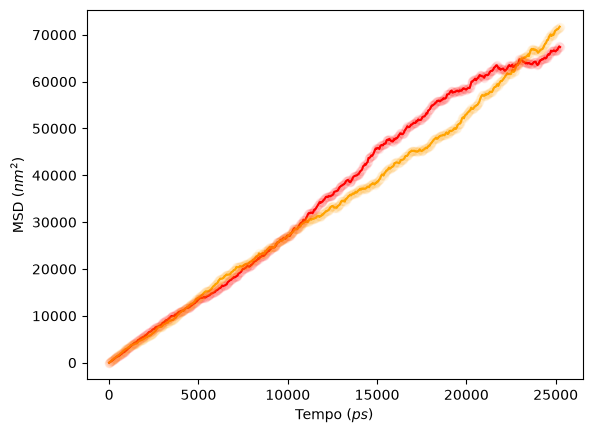

In [102]:
#Gráfico MSDxtime

tau = 1
rf = 1
r0=1
#Para n_rounds = 200

with open(f"out_kmc3D_{rf}_{tau}.pkl", "rb") as f:
    outs = pickle.load(f)

colors = ['red','orange']
for i in range(images):
    print(i)
    MSD_list = np.asarray(outs[i]['MSD_list_mean']).ravel()
    T_list = np.asarray(outs[i]['T_list_mean']).ravel()
    erros_posi = outs[i]['erro_D']*T_list
    erros_neg = outs[i]['erro_D']*T_list
    erro_D = outs[i]['erro_D']
    erros = np.array([erro_D])

    #plt.errorbar(T_list, MSD_list, yerr=erros, fmt='o', alpha = 0.1)
    plt.plot(T_list,MSD_list, alpha = 1, c = colors[i])
    plt.errorbar(T_list, MSD_list, yerr=erros,  c = colors[i], fmt='o-', alpha = 0.05)

#plt.gca().set_xscale('log')
#plt.gca().set_yscale('log')
#plt.xlim(1000,2000)
plt.xlabel(r"Tempo $(ps)$")
plt.ylabel(r"MSD $(nm^2)$")

plt.show()




0
1


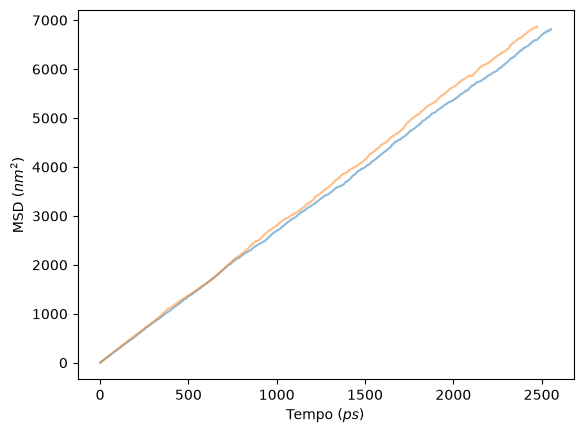

In [ ]:
#Gráfico MSDxtime

tau = 1
rf = 1
r0=1
#Para n_rounds = 2000

with open(f"out_kmc3D_{rf}_{tau}.pkl", "rb") as f:
    outs = pickle.load(f)

for i in range(images):
    print(i)
    MSD_list = np.asarray(outs[i]['MSD_list_mean']).ravel()
    T_list = np.asarray(outs[i]['T_list_mean']).ravel()
    plt.plot(T_list,MSD_list, alpha = 0.5)

plt.xlabel(r"Tempo $(ps)$")
plt.ylabel(r"MSD $(nm^2)$")

plt.show()

In [16]:
tau = 1
rf = 1
r0=1
#Teste tamanho dos arrays de output

with open(f"out_kmc3D_{rf}_{tau}.pkl", "rb") as f:
    outs = pickle.load(f)

for i in range(images):
    print(i)
    MSD_list = np.asarray(outs[i]['MSD_list_mean']).ravel()
    T_list = np.asarray(outs[i]['T_list_mean']).ravel()
    k2_list = np.asarray(outs[i]['kappa2_Dfinal']).ravel()
    #print(MSD_list)
    #print(T_list)
    print(k2_list)
    print(len(MSD_list), len(T_list), len(k2_list))

    

0
[0.44515142]
500 500 1
1
[0.46255157]
500 500 1


In [69]:
#########################################
# Testing the 2/3 for static lattice with no emission for diferent rounds
##########################################
tau = 1
rf = 1
r0=1
n=12
celula = 3

LOAD_FIXED_KAPPA=False
FIXED_KAPPA = 2/3
save = False
cutoff = r0
krot_dip = 0
PBC = [0,1,2]
L = r0*np.array([n,n,n])
nrounds = 100
nsteps_max = 10000000
dim = len(L)

Ds,Lds = [],[]

images = 3
outs = []
for i in range(images):
    syst = ld.System(save=save,RF=rf,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip, nsteps_max= nsteps_max)
    syst.make_lattice()
    results = Parallel(n_jobs=10,verbose=0)(delayed(kmc.kmc_run_fluor)(syst) for _ in range(nrounds))
    out_dict = kmc.process_results(results,dim=len(L),RF=rf,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)
    outs.append(out_dict)
with open(f"out_kmc3D_{rf}_{tau}_{celula}.pkl", "wb") as f:
    pickle.dump(outs, f)



this program run with <Kappa^2> = 0.66651
DONE LOADING LATTICE
MSD_init = 1.00 MSD_final = 7245697.54
Dana = 0.67 Dfinal = 0.49
LDana =0.82 LDcalc=0.70
kappa2 =0.49
this program run with <Kappa^2> = 0.66637
DONE LOADING LATTICE
MSD_init = 1.00 MSD_final = 6215141.02
Dana = 0.67 Dfinal = 0.41
LDana =0.82 LDcalc=0.64
kappa2 =0.41
this program run with <Kappa^2> = 0.66591
DONE LOADING LATTICE
MSD_init = 1.00 MSD_final = 7012222.76
Dana = 0.67 Dfinal = 0.46
LDana =0.82 LDcalc=0.68
kappa2 =0.46


[0.30630106 0.41996809 0.48742986 0.581153   0.55888889 0.52716086
 0.51003356 0.48239839 0.45791963 0.48459801 0.47322794 0.46121716
 0.45904995 0.45757503 0.44422279 0.44499655 0.43513046 0.42647378
 0.43212924 0.45339418 0.44996398 0.45451923 0.4425902  0.44037938
 0.43968989 0.43611992 0.44359529 0.43451953 0.43258131 0.43355893
 0.44060399 0.43621325 0.42877189 0.43148394 0.43349715 0.43002204
 0.43216381 0.43737379 0.44130332 0.44180384 0.44499292 0.45537176
 0.4565792  0.45627251 0.4614106  0.46168232 0.46205687 0.46004831
 0.45573314 0.45643445 0.46089463 0.45792627 0.45798259 0.45727494
 0.45168552 0.44688871 0.45319344 0.45214495 0.44743179 0.45086392
 0.45216514 0.45060068 0.45133115 0.44898617 0.45217473 0.44906301
 0.44911321 0.44559123 0.44260827 0.44259134 0.44004205 0.43888286
 0.43786725 0.43960449 0.44580931 0.44331256 0.45117965 0.4481464
 0.45592474 0.45305688 0.45430798 0.45318341 0.45231078 0.45267777
 0.45164089 0.45188857 0.45488241 0.4551226  0.45304605 0.45337

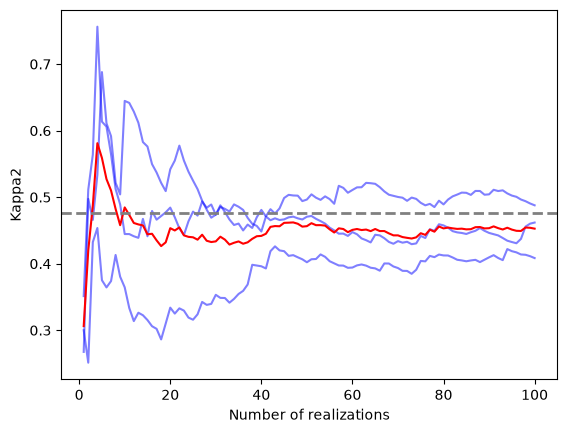

In [70]:
tau = 1
rf = 1
r0=1
n=12
celula = 3

with open(f"out_kmc3D_{rf}_{tau}_{celula}.pkl", "rb") as f:
    outs=pickle.load(f)

sum_kappas2 = np.zeros(nrounds)

for i in range(images):
    out_dict = outs[i]
    kappas2 = np.array(out_dict['kappa2_list_rounds'])[0]
    nrounds_array = np.arange(1,len(kappas2)+1)
    kappas2_means_image = np.cumsum(kappas2)/nrounds_array
    #kappas2_means_image_2 = np.array([np.mean(kappas2[0][:n]) for n in range(1, len(kappas2[0]) + 1)])
    
    ''''''
    #print(np.shape(kappas2))
    #print(kappas2[0], kappas2[-1])
    #print(kappas2_means_image[0],kappas2_means_image[-1])
    #print(len(kappas2))
    #print(len(nrounds_array))
    #print(np.shape(np.cumsum(kappas2_means_image)))
    ''''''

    sum_kappas2 += kappas2_means_image
    plt.plot(nrounds_array,kappas2_means_image,c='blue',alpha=0.5)

kappa2_means_total = sum_kappas2/images
print(kappa2_means_total)
plt.xlabel('Number of realizations')
plt.ylabel('Kappa2')
#Plot the mean of the imagens
plt.plot(nrounds_array,kappa2_means_total, c = 'red')
plt.axhline(0.476, linestyle = '--', c = 'gray', linewidth = 2)
plt.savefig(f'graf_rounds_{nrounds}_{images}_{nsteps_max}')
plt.show()


    
    

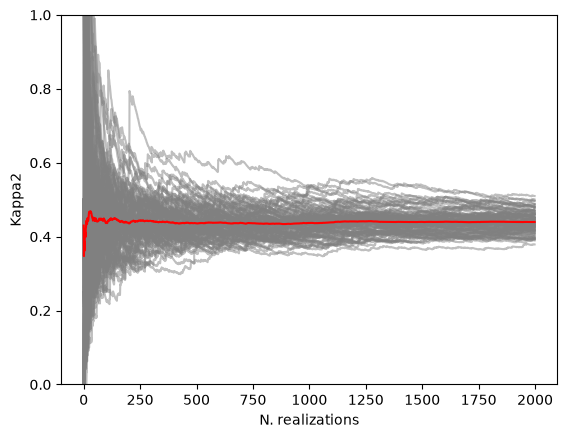

0.4396898449224612


In [ ]:
#ploting kappa with the images
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import importlib
import pickle

##########################################
tau = 1
rf = 1
r0=1
n=30
nrounds = 2000#00
images = 100
with open(f"out_kmc1D_{rf}_{tau}.pkl", "rb") as f:
    outs=pickle.load(f)

D_nokappa=(1/tau)*(((rf)**6)/(r0**4))
cums = np.zeros(nrounds)
Ld_ana_wihtoutkappa = (rf**3)/(r0**2)

for i in range(images):
    out_dict = outs[i]
    Ds = np.array([x for x in out_dict['D']])
    Dlist = np.array([x[0] for x in out_dict['Dlist']])
    kappa2_from_out = np.array([x for x in out_dict['kappa2_list_MSD']])
    mean_from_image = np.array([np.mean(kappa2_from_out[:n]) for n in range(1,len(kappa2_from_out)) ])
    plt.plot(np.arange(len(mean_from_image)),mean_from_image,c='grey',alpha=0.5)

    
    cums+=kappa2_from_out#Lds
cums  = cums/images
means = np.array([ np.mean(cums[:n]) for n in range(1,len(cums)) ])

plt.xlabel('N. realizations')
plt.ylabel('Kappa2')
plt.ylim(0,1)
plt.plot(np.arange(len(means)),means,c='r')
plt.show()
print(means[-1])